# Sala Segura: análise dos logs de acesso

Notebook da disciplina Hardware Architecture (Atitus). Lê os eventos gerados pelo sistema de controle
de acesso da sala do projeto e responde as perguntas do enunciado.

Fonte dos dados, em ordem de preferência:

1. API do servidor Flask (`/api/eventos.csv`), se estiver no ar;
2. arquivo `dados/acessos.csv` exportado pelo painel.

Cada linha é um evento: `entrada`, `saida` (com `duracao_segundos`), `acesso_negado`
(colaborador cadastrado sem permissão), `invasao` (tag desconhecida), `movimento_sem_cracha` ou `campainha`.

In [1]:
import io
import requests
import pandas as pd
import matplotlib.pyplot as plt

SERVIDOR = "http://127.0.0.1:5000"   # troque pelo IP do servidor, se preciso
ARQUIVO_LOCAL = "dados/acessos.csv"

def carregar():
    try:
        r = requests.get(f"{SERVIDOR}/api/eventos.csv", timeout=3)
        r.raise_for_status()
        print("Dados carregados da API")
        return pd.read_csv(io.StringIO(r.text), dtype={"tag_rfid": str})
    except requests.RequestException:
        print("API indisponível, usando o CSV local")
        return pd.read_csv(ARQUIVO_LOCAL, dtype={"tag_rfid": str})

df = carregar()
df["data_hora"] = pd.to_datetime(df["data_hora"])
df["data"] = df["data_hora"].dt.date
df["hora"] = df["data_hora"].dt.hour
print(f"{len(df)} eventos de {df['data'].min()} a {df['data'].max()}")
df.head()

Dados carregados da API
53 eventos de 2026-10-19 a 2026-10-24


,id,data_hora,tipo,tag_rfid,colaborador_id,nome,duracao_segundos,origem,detalhe,recebido_em,data,hora
0,7,2026-10-19 08:01:00,acesso_negado,333333333333,3.0,Patrick M.,NaN,simulador,NaN,2026-10-26 20:43:54,2026-10-19,8
1,1,2026-10-19 08:03:00,entrada,111111111111,1.0,Luiz Eduardo Tremea,NaN,simulador,NaN,2026-10-26 20:43:54,2026-10-19,8
2,2,2026-10-19 09:38:00,saida,111111111111,1.0,Luiz Eduardo Tremea,5700.0,simulador,NaN,2026-10-26 20:43:54,2026-10-19,9
3,3,2026-10-19 10:19:00,entrada,111111111111,1.0,Luiz Eduardo Tremea,NaN,simulador,NaN,2026-10-26 20:43:54,2026-10-19,10
4,4,2026-10-19 11:41:00,saida,111111111111,1.0,Luiz Eduardo Tremea,4920.0,simulador,NaN,2026-10-26 20:43:54,2026-10-19,11


## Visão geral

In [2]:
df["tipo"].value_counts()

tipo
entrada          15
saida            15
acesso_negado    13
invasao           7
campainha         3
Name: count, dtype: int64

In [3]:
# Eventos por dia e tipo
por_dia = df.pivot_table(index="data", columns="tipo", values="id", aggfunc="count", fill_value=0)
por_dia

tipo,acesso_negado,campainha,entrada,invasao,saida
data,,,,,
2026-10-19,1,1,3,0,3
2026-10-20,0,1,3,2,3
2026-10-21,2,1,2,1,2
2026-10-22,6,0,3,1,3
2026-10-23,4,0,4,2,4
2026-10-24,0,0,0,1,0


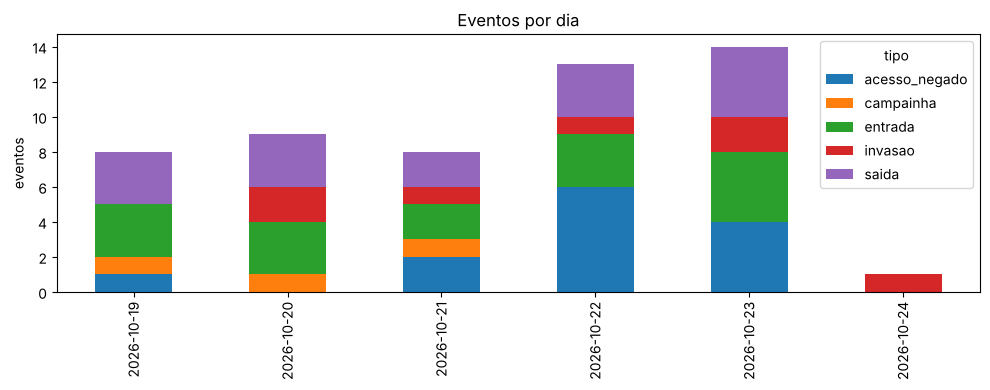

In [4]:
ax = por_dia.plot(kind="bar", stacked=True, figsize=(10, 4), title="Eventos por dia")
ax.set_xlabel("")
ax.set_ylabel("eventos")
plt.tight_layout()
plt.show()

## Perguntas do enunciado

Troque `DIA` e `COLABORADOR` para consultar outro dia ou outra pessoa.

In [5]:
# Dia com mais movimento no conjunto de dados (so para ter um exemplo preenchido)
DIA = df[df["tipo"] == "entrada"]["data"].value_counts().idxmax()
COLABORADOR = "Luiz Eduardo Tremea"
dia_df = df[df["data"] == DIA]
print("Dia analisado:", DIA)

Dia analisado: 2026-10-23


### 1. Quantas pessoas entraram na sala no dia?

In [6]:
entradas = dia_df[dia_df["tipo"] == "entrada"]
print(f"{entradas['nome'].nunique()} pessoa(s) distinta(s), em {len(entradas)} entrada(s)")
entradas.groupby("nome").size().rename("entradas")

2 pessoa(s) distinta(s), em 4 entrada(s)


nome
Bruno Benetti          3
Luiz Eduardo Tremea    1
Name: entradas, dtype: int64

### 2. Quantas pessoas saíram da sala no dia?

In [7]:
saidas = dia_df[dia_df["tipo"] == "saida"]
print(f"{saidas['nome'].nunique()} pessoa(s) distinta(s), em {len(saidas)} saída(s)")
saidas.groupby("nome").size().rename("saidas")

2 pessoa(s) distinta(s), em 4 saída(s)


nome
Bruno Benetti          3
Luiz Eduardo Tremea    1
Name: saidas, dtype: int64

### 3. Quanto tempo um colaborador ficou na sala no dia?

In [8]:
def tempo_na_sala(df, nome, dia):
    s = df[(df["tipo"] == "saida") & (df["nome"] == nome) & (df["data"] == dia)]
    return pd.to_timedelta(s["duracao_segundos"].sum(), unit="s")

print(f"{COLABORADOR} ficou {tempo_na_sala(df, COLABORADOR, DIA)} na sala em {DIA}")

# Tempo de todos no dia
(dia_df[dia_df["tipo"] == "saida"]
   .groupby("nome")["duracao_segundos"].sum()
   .pipe(lambda s: pd.to_timedelta(s, unit="s"))
   .rename("tempo_na_sala"))

Luiz Eduardo Tremea ficou 0 days 01:45:00 na sala em 2026-10-23


nome
Bruno Benetti         0 days 06:39:00
Luiz Eduardo Tremea   0 days 01:45:00
Name: tempo_na_sala, dtype: timedelta64[s]

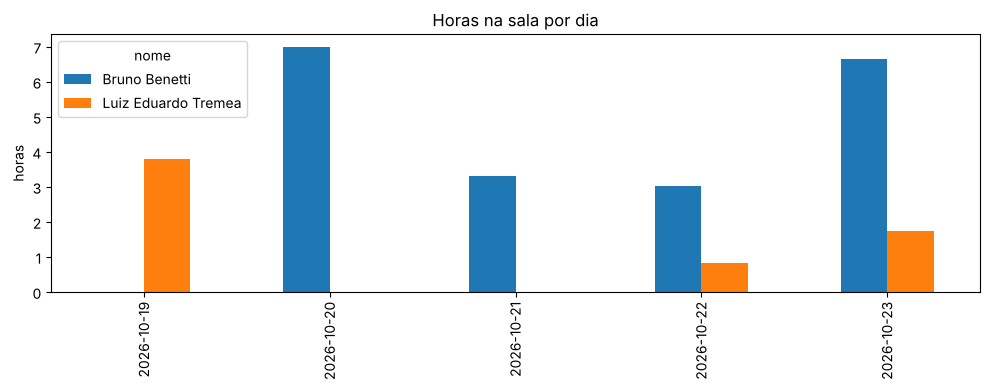

nome,Bruno Benetti,Luiz Eduardo Tremea
data,,
2026-10-19,0.00,3.80
2026-10-20,7.00,0.00
2026-10-21,3.30,0.00
2026-10-22,3.02,0.83
2026-10-23,6.65,1.75


In [9]:
# Tempo diário por colaborador em todo o período (em horas)
tempo = (df[df["tipo"] == "saida"]
           .pivot_table(index="data", columns="nome", values="duracao_segundos", aggfunc="sum", fill_value=0) / 3600)
ax = tempo.plot(kind="bar", figsize=(10, 4), title="Horas na sala por dia")
ax.set_ylabel("horas")
ax.set_xlabel("")
plt.tight_layout()
plt.show()
tempo.round(2)

### 4. Quantas tentativas de acesso negado ocorreram no dia?

In [10]:
negados = dia_df[dia_df["tipo"] == "acesso_negado"]
print(f"{len(negados)} tentativa(s) de acesso negado em {DIA}")
negados[["data_hora", "nome", "tag_rfid"]]

4 tentativa(s) de acesso negado em 2026-10-23


,data_hora,nome,tag_rfid
42,2026-10-23 10:15:00,Patrick M.,333333333333
44,2026-10-23 12:47:00,Ana Souza,444444444444
47,2026-10-23 16:34:00,Ana Souza,444444444444
49,2026-10-23 17:27:00,Ana Souza,444444444444


### 5. Quantas tentativas de invasão ocorreram no dia?

In [11]:
invasoes = dia_df[dia_df["tipo"] == "invasao"]
print(f"{len(invasoes)} tentativa(s) de invasão em {DIA}")
invasoes[["data_hora", "tag_rfid"]]

2 tentativa(s) de invasão em 2026-10-23


,data_hora,tag_rfid
50,2026-10-23 18:14:00,88120033421
51,2026-10-23 22:05:00,734528190


### 6. Quais colaboradores não autorizados mais tentaram acessar a sala no dia?

In [12]:
ranking = (dia_df[dia_df["tipo"] == "acesso_negado"]
             .groupby("nome").size()
             .sort_values(ascending=False)
             .rename("tentativas"))
ranking

nome
Ana Souza     3
Patrick M.    1
Name: tentativas, dtype: int64

## Extras: padrões no período inteiro

In [13]:
# Ranking geral de quem mais tentou sem permissão
df[df["tipo"] == "acesso_negado"].groupby("nome").size().sort_values(ascending=False).rename("tentativas")

nome
Ana Souza     7
Patrick M.    6
Name: tentativas, dtype: int64

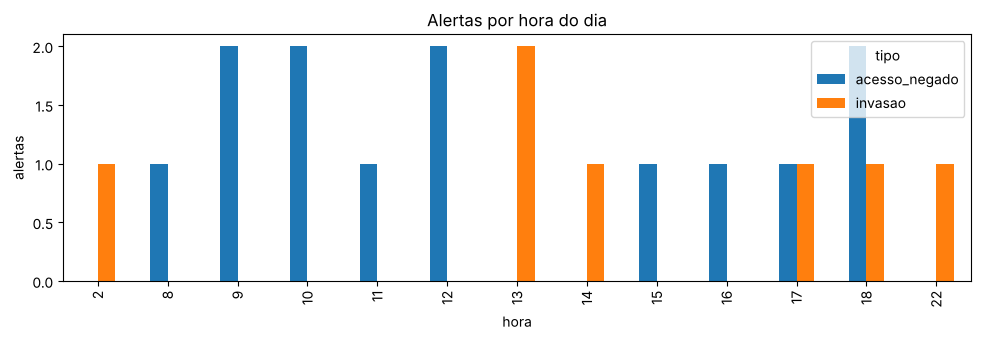

In [14]:
# Em que horas acontecem os alertas (invasao + acesso negado)?
alertas = df[df["tipo"].isin(["invasao", "acesso_negado"])]
ax = alertas.groupby(["hora", "tipo"]).size().unstack(fill_value=0).plot(
    kind="bar", figsize=(10, 3.5), title="Alertas por hora do dia")
ax.set_xlabel("hora")
ax.set_ylabel("alertas")
plt.tight_layout()
plt.show()

In [15]:
# Tags desconhecidas que mais apareceram (candidatas a investigacao)
df[df["tipo"] == "invasao"]["tag_rfid"].value_counts().rename("tentativas")

tag_rfid
501277364      2
88120033421    2
734528190      2
9900112233     1
Name: tentativas, dtype: int64

In [16]:
# Resumo diario em uma tabela so
resumo = pd.DataFrame({
    "pessoas_entraram": df[df["tipo"] == "entrada"].groupby("data")["nome"].nunique(),
    "entradas": df[df["tipo"] == "entrada"].groupby("data").size(),
    "saidas": df[df["tipo"] == "saida"].groupby("data").size(),
    "acessos_negados": df[df["tipo"] == "acesso_negado"].groupby("data").size(),
    "invasoes": df[df["tipo"] == "invasao"].groupby("data").size(),
    "horas_na_sala": df[df["tipo"] == "saida"].groupby("data")["duracao_segundos"].sum() / 3600,
}).fillna(0).round(2)
resumo

,pessoas_entraram,entradas,saidas,acessos_negados,invasoes,horas_na_sala
data,,,,,,
2026-10-19,1.0,3.0,3.0,1.0,0.0,3.80
2026-10-20,1.0,3.0,3.0,0.0,2.0,7.00
2026-10-21,1.0,2.0,2.0,2.0,1.0,3.30
2026-10-22,2.0,3.0,3.0,6.0,1.0,3.85
2026-10-23,2.0,4.0,4.0,4.0,2.0,8.40
2026-10-24,0.0,0.0,0.0,0.0,1.0,0.00
